# Multi-View VAE
## Download data


In [1]:
%pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://download.pytorch.org/whl/cu118
ERROR: Could not find a version that satisfies the requirement torchaudio (from versions: none)

[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
ERROR: No matching distribution found for torchaudio
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import random
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE


In [3]:
from pathlib import Path
import random
import time
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

torch.set_num_threads(min(4, torch.get_num_threads()))

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
    
    
# Intitialize params    
batch_size = 32
dimz = 20
var_x = 0.1
lr = 1e-3
epochs = 20

In [4]:
mnist_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

svhn_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

data_dir = Path('./data')

mnist_train = datasets.MNIST(root = data_dir, train = True, download = True, transform = mnist_transform)
mnist_test = datasets.MNIST(root = data_dir, train = False, download = True, transform = mnist_transform)
svhn_train = datasets.SVHN(root = data_dir, split = 'train', download = True, transform = svhn_transform)
svhn_test = datasets.SVHN(root = data_dir, split = 'test', download = True, transform = svhn_transform)

In [5]:
mnist_train_ids, mnist_val_ids = train_test_split(
    np.arange(len(mnist_train)), test_size=0.1, random_state=SEED, stratify=mnist_train.targets.numpy()
)

svhn_train_ids, svhn_val_ids = train_test_split(
    np.arange(len(svhn_train)), test_size=0.1, random_state=SEED, stratify=svhn_train.labels
)

class PairedDataset(Dataset):
    def __init__(self, mnist, svhn, mnist_ids = None, svhn_ids = None, seed = 42):
        self.mnist = mnist
        self.svhn = svhn
        if mnist_ids is None:
            mnist_ids = np.arange(len(mnist))
        if svhn_ids is None:
            svhn_ids = np.arange(len(svhn))
        svhn_ids = np.asarray(svhn_ids, dtype=int)
        rng = np.random.default_rng(seed)
        
        candidates = {}
        for digit in range(10):
            candidates[digit] = svhn_ids[svhn.labels[svhn_ids] == digit]
            assert len(candidates[digit]) > 0, f"No SVHN images for digit {digit}"
        
        self.pairs = []
        for i in mnist_ids:
            label = int(mnist.targets[i])
            j = int(rng.choice(candidates[label]))
            self.pairs.append((int(i), j))
            
    def __len__(self):
        return len(self.pairs)
    
    def __getitem__(self, idx):
        i, j = self.pairs[idx]
        x_mnist, label_mnist = self.mnist[i]
        x_svhn, label_svhn = self.svhn[j]
        assert label_mnist == int(label_svhn), f"Labels do not match: {label_mnist} != {label_svhn}"
        return x_mnist, x_svhn, int(label_mnist)
    
paired_train = PairedDataset(mnist_train, svhn_train, mnist_train_ids, svhn_train_ids, seed=SEED)
paired_val = PairedDataset(mnist_train, svhn_train, mnist_val_ids, svhn_val_ids, seed=SEED)
paired_test = PairedDataset(mnist_test, svhn_test, None, None, seed=SEED)


# Verify every pair using labels, without loading every image.
for dataset in [paired_train, paired_val, paired_test]:
    assert all(int(dataset.mnist.targets[i]) == int(dataset.svhn.labels[j])
               for i, j in dataset.pairs)
assert set(mnist_train_ids).isdisjoint(mnist_val_ids)
assert set(svhn_train_ids).isdisjoint(svhn_val_ids)
print("All pairs have matching labels; training and validation sources are disjoint.")

# Random subsets keep the practice run short, including a shuffled test subset.
def small_subset(dataset, size, seed):
    rng = np.random.default_rng(seed)
    ids = rng.permutation(len(dataset))[:min(size, len(dataset))].tolist()
    return Subset(dataset, ids)

train_data = paired_train
val_data = paired_val
test_data = paired_test
trainloader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                         generator=torch.Generator().manual_seed(SEED), num_workers=0)
valloader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=0)
testloader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=0)
print("Pairs used: train", len(train_data), "validation", len(val_data), "test", len(test_data))


All pairs have matching labels; training and validation sources are disjoint.
Pairs used: train 54000 validation 6000 test 10000


MNIST (32, 3, 64, 64) SVHN (32, 3, 64, 64)


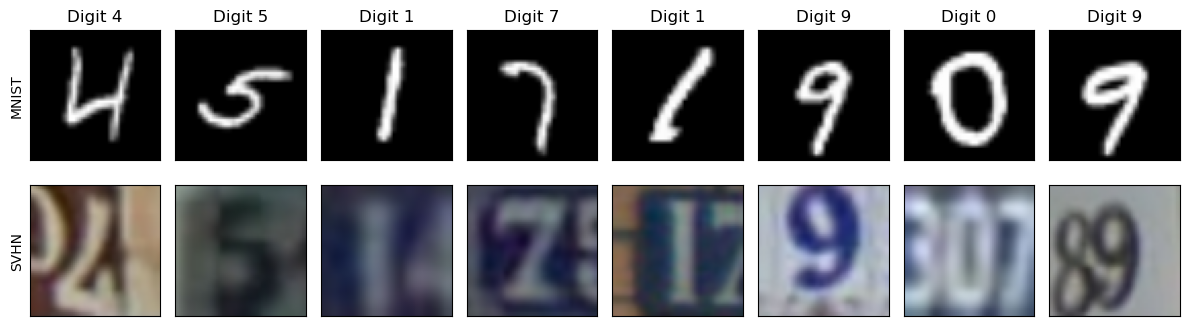

In [6]:
def show_rows(rows, row_names, labels=None, filename=None, n=8):
    n = min(n, min(len(row) for row in rows))
    fig, axes = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.8 * len(rows)), squeeze=False)
    for r, (images, name) in enumerate(zip(rows, row_names)):
        for c in range(n):
            img = (images[c].detach().cpu() / 2 + 0.5).clamp(0, 1)
            axes[r, c].imshow(img.permute(1, 2, 0).numpy())
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])
            if r == 0 and labels is not None:
                axes[r, c].set_title("Digit " + str(int(labels[c])))
        axes[r, 0].set_ylabel(name)
    fig.tight_layout()
    if filename is not None:
        fig.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()

mnist_batch, svhn_batch, labels = next(iter(trainloader))
print("MNIST", tuple(mnist_batch.shape), "SVHN", tuple(svhn_batch.shape))
show_rows([mnist_batch, svhn_batch], ["MNIST", "SVHN"], labels, "paired_data.png")


In [7]:
class Encoder(nn.Module):
    def __init__(self, dimz, channels = 3, var_x = 0.1):
        super().__init__()

        self.dimz = dimz
        
        self.conv1 = nn.Conv2d(in_channels = channels, out_channels = 32, kernel_size=4, stride=2, padding=1)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(in_channels = 32, out_channels = 32, kernel_size=4, stride=2, padding=1)
        self.conv3 = nn.Conv2d(in_channels = 32, out_channels = 64, kernel_size=4, stride=2, padding=1)
        self.conv4 = nn.Conv2d(in_channels = 64, out_channels = 64, kernel_size=4, stride=2, padding=1)
        self.conv5 = nn.Conv2d(in_channels = 64, out_channels = 256, kernel_size=4, stride=1, padding=0)
        self.linear = nn.Linear(256, dimz * 2)
        self.sofplus = nn.Softplus()
        
    def forward(self, x):
        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z))
        z = self.relu(self.conv3(z))
        z = self.relu(self.conv4(z))
        z = self.relu(self.conv5(z))
        z = z.view(-1, 256)
        z = self.linear(z)
        
        return z
    
    def encode_and_sample(self, x, flag_sample=True):
        z = self.forward(x)
        mu, var = z[:, :self.dimz], self.sofplus(0.5* z[:, self.dimz:]) + 1e-6
        sample = None
        if flag_sample==True:
            eps = torch.randn_like(var)
            sample = mu + eps * torch.sqrt(var)
        return mu, var, sample

In [8]:
class decoder(nn.Module):
    
    def __init__(self,dimz,channels=3,var_x=0.1):
        
        super().__init__()

        
        self.linear = nn.Linear(dimz,256)
        self.relu = nn.ReLU()
        self.tanh = nn.Tanh()
        self.tconv1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=1,padding=0)
        self.tconv2 = nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2,padding=1)
        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2,padding=1)
        self.tconv4 = nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2,padding=1)
        self.tconv5 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2,padding=1)
        
    def forward(self,z):

        x = self.relu(self.linear(z).view(-1,256,1,1))
        x = self.relu(self.tconv1(x))
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))
        x = self.relu(self.tconv4(x))
        x = self.tanh(self.tconv5(x))   
        return x
    
    def decode(self,z):
        
        return self.forward(z)


In [9]:
def product_of_experts(mus, variances):
    precision = torch.ones_like(variances[0])
    
    weighted_mu = torch.zeros_like(mus[0])
    for mu, var in zip(mus, variances):
        precision += 1.0 / var
        weighted_mu += mu / var

    mu = weighted_mu / precision
    variance = 1.0 / precision

    return mu, variance

In [10]:
def eval_Gaussian_LL(x,mu_x,var_x):

    D = x.shape[1] * x.shape[2] * x.shape[3]   # Dimension of the image
    x = x.reshape(-1, D)
    mu_x = mu_x.reshape(-1, D)
    var_x = torch.ones_like(mu_x) * var_x
    cnt = D * np.log(2 * np.pi) + torch.sum(torch.log(var_x), dim=-1)
    logp_data = -0.5 * (cnt + torch.sum((x - mu_x) * var_x ** -1 * (x - mu_x), dim=-1))
    logp = torch.sum(logp_data)

    return logp,logp_data


In [11]:
class JointVAE(nn.Module):
    def __init__(self, dimz, channels=3, var_x=0.1):
        super().__init__()
        self.dimz = dimz
        self.var_x = var_x
        self.encoder_mnist = Encoder(dimz, channels, var_x)
        self.encoder_svhn = Encoder(dimz, channels, var_x)
        self.decoder_mnist = decoder(dimz, channels, var_x)
        self.decoder_svhn = decoder(dimz, channels, var_x)
        
    def infer(self, x_mnist, x_svhn):
        mus, variances = [], []
        if x_mnist is not None:
            mu, var, _ = self.encoder_mnist.encode_and_sample(x_mnist, flag_sample=False)
            mus.append(mu)
            variances.append(var)
        if x_svhn is not None:
            mu, var, _ = self.encoder_svhn.encode_and_sample(x_svhn, flag_sample=False)
            mus.append(mu)
            variances.append(var)
        if not mus:
            raise ValueError("Provide at least one image; use sample() for prior generation.")
        return product_of_experts(mus, variances)
    
    def forward(self, x_mnist=None, x_svhn=None, flag_sample=True):
        mu_z, var_z = self.infer(x_mnist, x_svhn)
        if flag_sample:
            z = mu_z + torch.randn_like(var_z) * torch.sqrt(var_z)
        else:
            z = mu_z
        mu_mnist = self.decoder_mnist.decode(z)
        mu_svhn = self.decoder_svhn.decode(z)
        return mu_mnist, mu_svhn, mu_z, var_z

    def loss_function(self, x_mnist, x_svhn, mu_mnist, mu_svhn, mu_z, var_z):
        logp_mnist, _ = eval_Gaussian_LL(x_mnist, mu_mnist, self.var_x)
        logp_svhn, _ = eval_Gaussian_LL(x_svhn, mu_svhn, self.var_x)
        reconstruction = -logp_mnist - logp_svhn
        KLz = -0.5 * torch.sum(1 + torch.log(var_z) - mu_z.pow(2) - var_z)
        n = x_mnist.shape[0]
        return (reconstruction + KLz) / n, reconstruction / n, KLz / n

    def paired_loss(self, x_mnist, x_svhn):
        # Targets stay the same; only the information given to the encoder changes.
        losses, recs, kls = [], [], []
        for input_mnist, input_svhn in [(x_mnist, x_svhn), (x_mnist, None), (None, x_svhn)]:
            outputs = self.forward(input_mnist, input_svhn)
            loss, rec, kl = self.loss_function(x_mnist, x_svhn, *outputs)
            losses.append(loss)
            recs.append(rec)
            kls.append(kl)
        return torch.stack(losses).mean(), torch.stack(recs).mean(), torch.stack(kls).mean()

    def sample(self, num_imgs):
        device = next(self.parameters()).device
        z = torch.randn(num_imgs, self.dimz, device=device)
        return self.decoder_mnist.decode(z), self.decoder_svhn.decode(z)
        

In [12]:
torch.manual_seed(SEED)
my_vae = JointVAE(dimz=dimz, var_x=var_x).to(device)
x_mnist = mnist_batch[:2].to(device)
x_svhn = svhn_batch[:2].to(device)
for a, b in [(x_mnist, x_svhn), (x_mnist, None), (None, x_svhn)]:
    with torch.no_grad():
        out_m, out_s, mu, var = my_vae(a, b)
    assert out_m.shape == out_s.shape == x_mnist.shape
    assert mu.shape == var.shape == (2, dimz)
    assert (var > 0).all()
loss, rec, kl = my_vae.paired_loss(x_mnist, x_svhn)
assert torch.isfinite(loss)
loss.backward()
for network in [my_vae.encoder_mnist, my_vae.encoder_svhn,
                my_vae.decoder_mnist, my_vae.decoder_svhn]:
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in network.parameters())
my_vae.zero_grad(set_to_none=True)
print("Shapes, missing-view routes, loss and gradients passed.")
print("Initial loss / reconstruction / KL:", loss.item(), rec.item(), kl.item())


Shapes, missing-view routes, loss and gradients passed.
Initial loss / reconstruction / KL: 54761.85546875 54757.76171875 4.091373920440674


In [ ]:
def run_epoch(model, loader, optimizer = None):
    training = optimizer is not None
    model.train(training)
    totals = np.zeros(3)
    n_pairs = 0
    for x_mnist, x_svhn, _ in loader:
        x_mnist = x_mnist.to(device)
        x_svhn = x_svhn.to(device)
        with torch.set_grad_enabled(training):
            loss, rec, kl = model.paired_loss(x_mnist, x_svhn)
            if training:
                optimizer.zero_grad()
            loss, rec, kl = model.paired_loss(x_mnist, x_svhn)
            if not torch.isfinite(loss):
                raise ValueError("Non-finite loss encountered.")
            if training:
                loss.backward()
                optimizer.step()
        n = x_mnist.shape[0]
        totals += np.array([loss.item(), rec.item(), kl.item()]) * n
        n_pairs += n
    return totals / n_pairs

optimizer = optim.Adam(my_vae.parameters(), lr=lr)
history = {"train": [], "val": []}
best_val = float("inf")
best_epoch = 0
checkpoint_path = 'joint_vae_best.pth'
start_time = time.time()

for epoch in range(epochs):
    print(f"Epoch {epoch + 1:02d}/{epochs} | elapsed {(time.time() - start_time) / 60:.1f} min", flush=True)
    train_metrics = run_epoch(my_vae, trainloader, optimizer)
    val_metrics = run_epoch(my_vae, valloader)
    history["train"].append(train_metrics.tolist())
    history["val"].append(val_metrics.tolist())
    if val_metrics[0] < best_val:
        best_val = float(val_metrics[0])
        best_epoch = epoch + 1
        torch.save(my_vae.state_dict(), checkpoint_path)
    print(f"Epoch {epoch + 1:02d}/{epochs} | train {train_metrics[0]:.2f} | "
          f"val {val_metrics[0]:.2f} | KL {train_metrics[2]:.2f} | "
          f"elapsed {(time.time() - start_time) / 60:.1f} min", flush=True)
    
my_vae.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
my_vae.eval()
run_info = {
    "seed": SEED, "dimz": dimz, "var_x": var_x,
    "lr": lr, "batch_size": batch_size, "epochs": epochs, "best_epoch": best_epoch,
    "train_pairs": len(train_data), "val_pairs": len(val_data), "test_pairs": len(test_data),
    "device": str(device), "torch_version": str(torch.__version__),
    "training_seconds": time.time() - start_time, "history": history,
}
(output_dir / "run_info.json").write_text(json.dumps(run_info, indent=2))
print("Restored best validation checkpoint, epoch", best_epoch)

Epoch 01/20 | elapsed 0.0 min


KeyboardInterrupt: 

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for i, name in enumerate(["Negative ELBO", "Reconstruction NLL", "KL divergence"]):
    for split in ["train", "val"]:
        axes[i].plot(range(1, epochs + 1), np.array(history[split])[:, i], label=split)
    axes[i].set_title(name)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Per pair (average of three routes)")
    axes[i].legend()
fig.tight_layout()
fig.savefig("training_curves.png", dpi=150)
plt.show()


In [ ]:
torch.manual_seed(SEED + 100)
test_metrics = run_epoch(my_vae, testloader)
print("Held-out negative ELBO / reconstruction NLL / KL:", test_metrics)

@torch.no_grad()
def evaluate_mse(model, loader):
    model.eval()
    totals = np.zeros((3, 2))
    count = 0
    for xm, xs, _ in loader:
        xm, xs = xm.to(device), xs.to(device)
        for route, (a, b) in enumerate([(xm, xs), (xm, None), (None, xs)]):
            rm, rs, _, _ = model(a, b, flag_sample=False)
            totals[route, 0] += ((rm - xm) ** 2).flatten(1).mean(1).sum().item() / 4
            totals[route, 1] += ((rs - xs) ** 2).flatten(1).mean(1).sum().item() / 4
        count += len(xm)
    return totals / count

mse = evaluate_mse(my_vae, testloader)
for name, values in zip(["Both inputs", "MNIST only", "SVHN only"], mse):
    print(f"{name:12s} | MNIST MSE {values[0]:.5f} | SVHN MSE {values[1]:.5f}")
run_info["test_negative_elbo_reconstruction_kl"] = test_metrics.tolist()
run_info["test_mse_rows_joint_mnist_svhn"] = mse.tolist()
(output_dir / "run_info.json").write_text(json.dumps(run_info, indent=2))


In [ ]:
mnist_batch, svhn_batch, labels = next(iter(testloader))
x_mnist, x_svhn = mnist_batch.to(device), svhn_batch.to(device)
my_vae.eval()
with torch.no_grad():
    rec_mnist, rec_svhn, _, _ = my_vae(x_mnist, x_svhn, flag_sample=False)
show_rows([mnist_batch, rec_mnist, svhn_batch, rec_svhn],
          ["MNIST input", "MNIST recon", "SVHN input", "SVHN recon"],
          labels, "reconstructions.png")


(tensor(268048.2188, grad_fn=<AddBackward0>), tensor(268046.1875), tensor(2.0325, grad_fn=<MulBackward0>))
(tensor(1907194.5000, grad_fn=<AddBackward0>), tensor(1907192.5000), tensor(2.0325, grad_fn=<MulBackward0>))


In [ ]:
torch.manual_seed(SEED + 101)
with torch.no_grad():
    generated_mnist, generated_svhn = my_vae.sample(8)
show_rows([generated_mnist, generated_svhn], ["Generated MNIST", "Generated SVHN"],
          filename="prior_generation.png")


In [ ]:
with torch.no_grad():
    _, mnist_to_svhn, _, _ = my_vae(x_mnist=x_mnist, flag_sample=False)
    svhn_to_mnist, _, _, _ = my_vae(x_svhn=x_svhn, flag_sample=False)
show_rows([mnist_batch, mnist_to_svhn, svhn_batch, svhn_to_mnist],
          ["MNIST input", "MNIST → SVHN", "SVHN input", "SVHN → MNIST"],
          labels, "cross_domain.png")

with torch.no_grad():
    mu, var = my_vae.infer(x_mnist=x_mnist[:1])
    z = mu + torch.randn(8, dimz, device=device) * torch.sqrt(var)
    variations = my_vae.decoder_svhn.decode(z)
show_rows([mnist_batch[:1].repeat(8, 1, 1, 1), variations],
          ["Same MNIST", "SVHN samples"], filename="cross_domain_variations.png")


Labels: [1, 0, 1, 7, 7, 4, 0, 4]


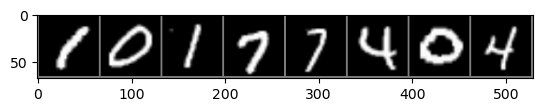

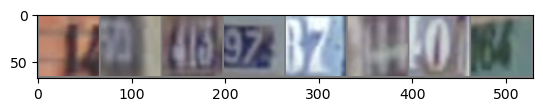

In [ ]:
@torch.no_grad()
def collect_latents(model, loader, max_pairs=500):
    model.eval()
    joint, mnist_only, svhn_only, labels = [], [], [], []
    count = 0
    for xm, xs, y in loader:
        take = min(len(y), max_pairs - count)
        xm, xs = xm[:take].to(device), xs[:take].to(device)
        joint.append(model.infer(xm, xs)[0].cpu())
        mnist_only.append(model.infer(x_mnist=xm)[0].cpu())
        svhn_only.append(model.infer(x_svhn=xs)[0].cpu())
        labels.append(y[:take])
        count += take
        if count >= max_pairs:
            break
    return [torch.cat(values).numpy() for values in [joint, mnist_only, svhn_only, labels]]

z_joint, z_mnist, z_svhn, digit_labels = collect_latents(my_vae, testloader)
z_all = np.concatenate([z_joint, z_mnist, z_svhn])
assert np.isfinite(z_all).all()
embedding = TSNE(n_components=2, perplexity=30, init="random",
                 learning_rate="auto", random_state=SEED).fit_transform(z_all)
assert np.isfinite(embedding).all()
n = len(digit_labels)
fig, ax = plt.subplots(figsize=(9, 6))
for i, (name, marker) in enumerate([("Both inputs", "o"), ("MNIST only", "^"), ("SVHN only", "x")]):
    points = embedding[i*n:(i+1)*n]
    scatter = ax.scatter(points[:, 0], points[:, 1], c=digit_labels,
                         cmap="tab10", vmin=-0.5, vmax=9.5, marker=marker,
                         s=14, alpha=0.65, label=name)
fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit")
ax.legend()
ax.set_title("t-SNE of held-out posterior means — " + ("quick run" if QUICK_RUN else "full run"))
ax.set_xlabel("t-SNE coordinate 1")
ax.set_ylabel("t-SNE coordinate 2")
fig.tight_layout()
fig.savefig( / "latent_tsne.png", dpi=150)
plt.show()
np.savez( / "latent_tsne.npz", embedding=embedding, labels=digit_labels,
         z_joint=z_joint, z_mnist=z_mnist, z_svhn=z_svhn)


In [ ]:
my_vae = VAE(dimz=2)

reconstruction, mu, var = my_vae(mnist_batch)
loss, reconstruction_loss, kl = my_vae.loss_function(
    mnist_batch, reconstruction, mu, var
)